In [9]:
from langgraph.graph import StateGraph,START,END
from langchain_openai import ChatOpenAI
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import PydanticOutputParser,StrOutputParser
from pydantic import BaseModel,Field
from typing import TypedDict,Literal,Annotated
from dotenv import load_dotenv

In [2]:
load_dotenv()

True

In [3]:
class SentimentSchema(BaseModel):
    sentiment : Literal['POSITIVE','NEGATIVE'] = Field(description='sentiment of the review')

In [4]:
class DiagnosisSchema(BaseModel):
    issue_type: Literal["UX", "Performance", "Bug", "Support", "Other"] = Field(description='The category of issue mentioned in the review')
    tone: Literal["angry", "frustrated", "disappointed", "calm"] = Field(description='The emotional tone expressed by the user')
    urgency: Literal["low", "medium", "high"] = Field(description='How urgent or critical the issue appears to be')

In [5]:
class ReviewState(TypedDict):
    review:str
    sentiment:str
    diagnosis:dict
    response:str

In [12]:
parser=PydanticOutputParser(pydantic_object=SentimentSchema)
llm=ChatOpenAI(model='gpt-4o')
str_parser=StrOutputParser()
diagnosis_parser=PydanticOutputParser(pydantic_object=DiagnosisSchema)

In [8]:
def analyze_sentiment(state:ReviewState):
    prompt=PromptTemplate(template="""return the sentiment of the following review : {review} . \n {format_instructions}""",
                          input_variables=['review'],
                          partial_variables={'format_instructions':parser.get_format_instructions()})
    chain=prompt | llm | parser
    response= chain.invoke({'review':state['review']})
    state['sentiment']=response.sentiment
    return state

In [11]:
def generate_positive_feedback(state:ReviewState):
    prompt=PromptTemplate(template="""generate a sweet positive feedback for given review : {review}""",
                              input_variables=['review'])

    chain=prompt | llm | str_parser
    state['response']=chain.invoke({'review':state['review']})
    return state

In [13]:
def generate_diagnosis(state:ReviewState):
    prompt = PromptTemplate(template="""Diagnose this negative review:\n\n{review}\n"
    "Return issue_type, tone, and urgency. \n {format_instructions}""",
    input_variables=['review'],
    partial_variables={'format_instructions':diagnosis_parser.get_format_instructions()}
    )

    chain =prompt | llm | diagnosis_parser
    response= chain.invoke({'review':state['review']})
    return  {'diagnosis': response.model_dump()}

In [24]:
def sentiment_check(state:ReviewState)-> Literal["generate_positive_feedback", "generate_diagnosis"]:
    sentiment=state['sentiment']

    if sentiment.lower()=='positive':
        return 'generate_positive_feedback'
    else:
        return 'generate_diagnosis'

In [ ]:
def generate_positive_feedback(state:ReviewState):
    prompt=PromptTemplate(template="""generate a sweet positive feedback for given review : {review}""",
                              input_variables=['review'])

    chain=prompt | llm | str_parser
    state['response']=chain.invoke({'review':state['review']})
    return state

In [41]:
def generate_negative_feedback(state:ReviewState):
    prompt=PromptTemplate(template="""You are a support assistant.The user had a '{issue_type}' issue, sounded '{tone}', and marked urgency as '{urgency}'.Write an empathetic, helpful resolution message.""",
                              input_variables=['issue_type','tone','urgency'])

    diagnosis = state['diagnosis']

    chain=prompt | llm | str_parser
    state['response']=chain.invoke({'issue_type':diagnosis['issue_type'],'tone':diagnosis['tone'],'urgency':diagnosis['urgency']})
    return state

In [42]:
graph=StateGraph(ReviewState)

In [43]:
# Add Nodes

graph.add_node('analyze_sentiment',analyze_sentiment)
graph.add_node('generate_positive_feedback',generate_positive_feedback)
graph.add_node('generate_diagnosis',generate_diagnosis)
graph.add_node('generate_negative_feedback',generate_negative_feedback)


# Add Edges

graph.add_edge(START,'analyze_sentiment')
graph.add_conditional_edges('analyze_sentiment',sentiment_check)
graph.add_edge('generate_positive_feedback',END)
graph.add_edge('generate_diagnosis','generate_negative_feedback')
graph.add_edge('generate_negative_feedback',END)



In [44]:
workflow=graph.compile()

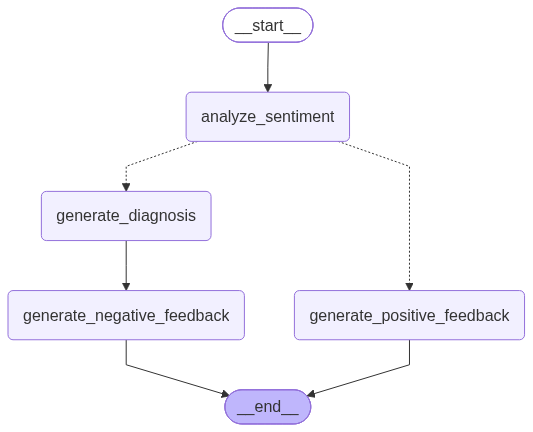

In [45]:
workflow

In [46]:
initial_state={'review':'The picture quality is disappointing, and the sound is very weak. The TV sometimes freezes while using streaming apps. I am not satisfied with this purchase'}

In [47]:
final_state=workflow.invoke(initial_state)

In [48]:
final_state

{'review': 'The picture quality is disappointing, and the sound is very weak. The TV sometimes freezes while using streaming apps. I am not satisfied with this purchase',
 'sentiment': 'NEGATIVE',
 'diagnosis': {'issue_type': 'Performance',
  'tone': 'disappointed',
  'urgency': 'medium'},
 'response': "I'm really sorry to hear that you're experiencing performance issues. I understand how frustrating this can be, and I want to help you resolve it as quickly as possible. Could you please provide some more details about the problem you're encountering? Specifically, any error messages you're seeing or actions that seem to trigger the issue. In the meantime, if you haven't already done so, restarting your device or application might help improve performance. Let's work together to get this resolved for you, so you can get back to what matters most."}